# Partie 2 : Transformer, génération de texte avec GPT-2

## Objectif

Dans la partie 1, les réseaux récurrents entraînés de zéro ne générent pas du texte arabe : ils répétaient les mêmes expressions et restaient en dessous d'une simple liste de mots fréquents. Ici on utilise un **Transformer pré-entraîné** (GPT-2) qui connaît déjà l'arabe, et on l'adapte à notre sujet (l'éducation au Maroc). Le travail demandé par le TP est :

1. charger un modèle GPT-2 pré-entraîné ;
2. le **fine-tuner** sur un dataset personnalisé ;
3. **générer un paragraphe** à partir d'une phrase donnée.

On ajoute une évaluation chiffrée (perplexité et BLEU) pour comparer le modèle avant et après fine-tuning, et pour le comparer aux modèles de la partie 1.

## Plan

1. Configuration
2. Chargement du modèle GPT-2 pré-entraîné
3. Dataset personnalisé
4. Fine-tuning
5. Génération d'un paragraphe à partir d'une phrase
6. Évaluation : perplexité et BLEU
7. Sauvegarde et bilan

## 1. Configuration

### 1.1 À propos de `pytorch-transformers`

Le TP et le tutoriel parlent de la bibliothèque `pytorch-transformers`. Cette bibliothèque a été renommée **`transformers`** (Hugging Face) et l'ancienne version n'est plus maintenue : elle ne s'installe pas correctement sur les versions récentes de Python. On utilise donc `transformers`. L'utilisation est la même que dans le tutoriel : un tokenizer, un modèle `GPT2LMHeadModel`, une boucle d'entraînement avec `AdamW` et un scheduler, puis la méthode `generate`.

### 1.2 Installation et imports

In [1]:
!pip -q install transformers accelerate

In [2]:
import os, re, json, random, time, copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import LambdaLR

import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.model_selection import GroupShuffleSplit
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

sns.set_theme(style="whitegrid")
print("transformers :", transformers.__version__, "| torch :", torch.__version__)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Périphérique :", device)
if device.type == "cpu":
    print("ATTENTION : pas de GPU, le fine-tuning sera très lent.")

transformers : 5.22.1 | torch : 2.14.1+cu130
Périphérique : cuda


### 1.3 Chemins des fichiers

On monte Google Drive pour retrouver le dataset de la partie 1 et on crée un dossier `resultats_partie2` pour les résultats et le modèle fine-tuné.

In [3]:
IN_COLAB = "google.colab" in str(get_ipython())
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/Projet_NLP_Education_Maroc/"
else:
    BASE_DIR = "./"

DATA_FILE = os.path.join(BASE_DIR, "dataset_education_maroc_full.csv")
PART1_DIR = os.path.join(BASE_DIR, "resultats_partie1")
OUT_DIR = os.path.join(BASE_DIR, "resultats_partie2")
MODEL_DIR = os.path.join(OUT_DIR, "gpt2_education_maroc")
os.makedirs(OUT_DIR, exist_ok=True)
print("Résultats dans :", OUT_DIR)

Mounted at /content/drive
Résultats dans : /content/drive/MyDrive/Projet_NLP_Education_Maroc/resultats_partie2


## 2. Chargement du modèle GPT-2 pré-entraîné

### 2.1 Choix du modèle

Le GPT-2 d'origine d'OpenAI a été entraîné surtout sur de l'anglais : il découpe très mal l'arabe. On utilise donc **AraGPT2-base** (`aubmindlab/aragpt2-base`), qui a exactement l'architecture de GPT-2 (12 couches, 12 têtes d'attention, contexte de 1024 mots, 135 millions de paramètres) mais qui a été pré-entraîné sur un grand corpus arabe (Wikipédia arabe, corpus d'articles de presse...). Il est compatible avec les classes `GPT2LMHeadModel` de `transformers`.

On charge deux copies : `base_model`, qu'on ne modifie jamais (pour comparer avant / après), et `model`, qu'on va fine-tuner.

In [4]:
MODEL_NAME = "aubmindlab/aragpt2-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# GPT-2 n'a pas de symbole de remplissage : on utilise le symbole de fin de texte
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
PAD_ID = tokenizer.pad_token_id
EOS_ID = tokenizer.eos_token_id

base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device).eval()
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Modèle : {MODEL_NAME}")
print(f"Paramètres : {n_params / 1e6:.0f} millions")
print("Taille du vocabulaire :", len(tokenizer))
print("Contexte maximal :", model.config.n_positions, "tokens")
print("Symbole de fin :", tokenizer.eos_token, "| id :", EOS_ID)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.50M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/4.52M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  553MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                         | Status     |  | 
----------------------------+------------+--+-
h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                         | Status     |  | 
----------------------------+------------+--+-
h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modèle : aubmindlab/aragpt2-base
Paramètres : 135 millions
Taille du vocabulaire : 64000
Contexte maximal : 1024 tokens
Symbole de fin : <|endoftext|> | id : 0


### 2.2 Le tokenizer

GPT-2 ne travaille pas avec des mots mais avec des **tokens** (morceaux de mots, appris par BPE). On regarde comment une phrase arabe est découpée, et combien de tokens il faut en moyenne par mot : c'est important, car la longueur maximale du modèle est donnée en tokens.

In [5]:
sentence = "يعتبر إصلاح التعليم في المغرب من أهم الأوراش الوطنية"
ids = tokenizer(sentence)["input_ids"]

print("Phrase :", sentence)
print("Nombre de mots  :", len(sentence.split()))
print("Nombre de tokens :", len(ids))
print("Tokens :", tokenizer.convert_ids_to_tokens(ids))
print("Retour au texte :", tokenizer.decode(ids))

Phrase : يعتبر إصلاح التعليم في المغرب من أهم الأوراش الوطنية
Nombre de mots  : 9
Nombre de tokens : 11
Tokens : ['ÙĬØ¹', 'ØªØ¨Ø±', 'ĠØ¥ØµÙĦØ§ØŃ', 'ĠØ§ÙĦØªØ¹ÙĦÙĬÙħ', 'ĠÙģÙĬ', 'ĠØ§ÙĦÙħØºØ±Ø¨', 'ĠÙħÙĨ', 'ĠØ£ÙĩÙħ', 'ĠØ§ÙĦØ£ÙĪØ±', 'Ø§Ø´', 'ĠØ§ÙĦÙĪØ·ÙĨÙĬØ©']
Retour au texte : يعتبر إصلاح التعليم في المغرب من أهم الأوراش الوطنية


### 2.3 Premier test : le modèle avant fine-tuning

Avant de l'adapter, on regarde ce que le modèle pré-entraîné écrit à partir d'une phrase sur l'éducation. On utilise un échantillonnage (*sampling*) avec `top_p` et `top_k`, qui choisit le mot suivant au hasard parmi les plus probables, ce qui donne des textes plus variés qu'un choix toujours identique. `no_repeat_ngram_size=3` interdit de répéter 3 mots de suite déjà écrits.

In [6]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
DIACRITICS_RE = re.compile(r"[\u0617-\u061A\u064B-\u0652\u0670]")
INVISIBLE_RE = re.compile(r"[\u200b-\u200f\u202a-\u202e]")
NON_ARABIC_RE = re.compile(r"[^\u0621-\u064A\s]")

def clean_text(text):
    """Même nettoyage que dans la partie 1 : lettres arabes seulement, sans voyelles ni tatwil."""
    text = URL_RE.sub(" ", str(text))
    text = INVISIBLE_RE.sub("", text)
    text = DIACRITICS_RE.sub("", text)
    text = text.replace("\u0640", "")
    text = NON_ARABIC_RE.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()

def normalize_arabic(text):
    text = re.sub("[إأآٱ]", "ا", text)
    return text.replace("ى", "ي").replace("ة", "ه")


GEN_KWARGS = dict(do_sample=True, top_p=0.92, top_k=50, temperature=0.8,
                  no_repeat_ngram_size=3, repetition_penalty=1.2)

def write_paragraph(sentence, which_model, max_new_tokens=120, seed=SEED, **kwargs):
    """Génère un paragraphe à partir d'une phrase de départ."""
    set_seed(seed)
    prompt = clean_text(sentence)
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    params = {**GEN_KWARGS, **kwargs}
    with torch.no_grad():
        out = which_model.generate(**enc, max_new_tokens=max_new_tokens,
                                   pad_token_id=PAD_ID, **params)
    return tokenizer.decode(out[0], skip_special_tokens=True)

test_prompt = "تعتبر الجامعة المغربية"
print("Modèle PRÉ-ENTRAÎNÉ (avant fine-tuning)\n")
print(write_paragraph(test_prompt, base_model))

Modèle PRÉ-ENTRAÎNÉ (avant fine-tuning)

تعتبر الجامعة المغربية - فرع فاس ( 13 كلم ) ، وجهة جامعية متميزة في مجال المعلوميات . تعد هذه المدينة مركزا متميزا للتعليم والتكوين والبحث العلمي على الصعيد الوطني والدولي بفضل موقعها الجغرافي الاستراتيجي الذي يعد قبلة الباحثين والأكاديميين والعلماء من مختلف دول العالم ومن بلدان متعددة .


## 3. Dataset personnalisé

### 3.1 Corpus

Dataset : on utilise celui de la partie 1, des passages en arabe sur **l'éducation au Maroc** (Wikipédia arabe et articles de la revue RMPRS). On applique le même nettoyage que dans la partie 1 (lettres arabes seulement, sans voyelles ni tatwil), mais **sans** stemming ni lemmatisation, car GPT-2 a besoin de mots complets. On ne normalise pas non plus les lettres (on garde « ة » et « أ »), pour rester proche de l'arabe sur lequel GPT-2 a été entraîné.

In [7]:
df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")
df["clean"] = df["Text"].apply(clean_text)
df["words"] = df["clean"].str.split()

print("Nombre de passages :", len(df), "| articles :", df["article_id"].nunique())
print("Mots par passage (moyenne) :", round(df["words"].str.len().mean(), 1))
print("\nExemple :\n", df["clean"].iloc[0][:200])

Nombre de passages : 342 | articles : 93
Mots par passage (moyenne) : 106.5

Exemple :
 جامعة محمد الخامس هي جامعة مغربية تأسست سنة بموجب ظهير ملكي شريف تقع وسط العاصمة المغربية الرباط وتعد ثاني أقدم الجامعات الحديثة بالمغرب بعد جامعة القرويين سميت بهذا الاسم نسبة للملك المغربي الراحل مح


### 3.2 Même séparation que la partie 1

On refait exactement la même séparation par article que dans la partie 1 (même graine, lue dans `config.json`). Comme ça, le modèle n'est jamais évalué sur des articles qu'il a vus pendant le fine-tuning, et les résultats sont comparables avec les modèles de la partie 1. On doit retrouver 246 passages pour le train, 37 pour la validation et 59 pour le test.

In [8]:
config_path = os.path.join(PART1_DIR, "config.json")
split_seed = json.load(open(config_path, encoding="utf-8"))["split_seed"] if os.path.exists(config_path) else 303
groups = df["article_id"].reset_index(drop=True)

def try_split(seed):
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=seed)
    train_idx, tmp_idx = next(gss1.split(np.zeros(len(df)), groups=groups))
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=seed)
    v, t = next(gss2.split(np.zeros(len(tmp_idx)), groups=groups[tmp_idx]))
    return train_idx, tmp_idx[v], tmp_idx[t]

train_idx, val_idx, test_idx = try_split(split_seed)
print("Graine :", split_seed)
print("Passages : train", len(train_idx), "| validation", len(val_idx), "| test", len(test_idx))

assert not (set(groups[train_idx]) & set(groups[test_idx]))
assert not (set(groups[train_idx]) & set(groups[val_idx]))
assert not (set(groups[val_idx]) & set(groups[test_idx]))
print("Aucun article en commun entre les ensembles.")

Graine : 303
Passages : train 246 | validation 37 | test 59
Aucun article en commun entre les ensembles.


### 3.3 Tokenisation des passages

Chaque passage est converti en tokens, puis on ajoute à la fin le symbole de fin de texte (`<|endoftext|>`), pour que le modèle apprenne aussi à terminer un texte. On regarde d'abord la longueur en tokens, pour choisir une longueur maximale `MAX_TOKENS` : les passages plus longs sont coupés.

In [9]:
token_lengths = df["clean"].apply(lambda t: len(tokenizer(t, add_special_tokens=False)["input_ids"]))
print("Tokens par passage : moyenne", round(token_lengths.mean()), "| max", token_lengths.max())
print("Tokens par mot (moyenne) :", round(token_lengths.sum() / df["words"].str.len().sum(), 2))

MAX_TOKENS = int(np.percentile(token_lengths.iloc[train_idx], 95)) + 1
MAX_TOKENS = min(MAX_TOKENS, 512)
print("Longueur maximale retenue :", MAX_TOKENS, "tokens")

def encode_passage(text):
    ids = tokenizer(text, add_special_tokens=False)["input_ids"][:MAX_TOKENS - 1]
    return ids + [EOS_ID]

train_data = [encode_passage(df["clean"].iloc[i]) for i in train_idx]
val_data   = [encode_passage(df["clean"].iloc[i]) for i in val_idx]
test_data  = [encode_passage(df["clean"].iloc[i]) for i in test_idx]

Tokens par passage : moyenne 121 | max 162
Tokens par mot (moyenne) : 1.14
Longueur maximale retenue : 150 tokens


### 3.4 DataLoaders

Les passages n'ont pas tous la même longueur. Dans chaque batch, on complète les plus courts avec le symbole de remplissage. On crée aussi les `labels` : pour un modèle de langage, la cible est le texte lui-même (le modèle prédit chaque token à partir des précédents). Les positions de remplissage reçoivent la valeur `-100`, que PyTorch ignore dans le calcul de la perte.

In [10]:
def collate(batch):
    max_len = max(len(x) for x in batch)
    input_ids = torch.full((len(batch), max_len), PAD_ID, dtype=torch.long)
    attention = torch.zeros((len(batch), max_len), dtype=torch.long)
    labels = torch.full((len(batch), max_len), -100, dtype=torch.long)
    for i, x in enumerate(batch):
        t = torch.tensor(x)
        input_ids[i, :len(x)] = t
        attention[i, :len(x)] = 1
        labels[i, :len(x)] = t
    return input_ids, attention, labels

BATCH_SIZE = 8
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader   = DataLoader(val_data, batch_size=8, collate_fn=collate)
test_loader  = DataLoader(test_data, batch_size=8, collate_fn=collate)

ids, att, lab = next(iter(train_loader))
print("Un batch :", tuple(ids.shape), "| tokens utiles :", int(att.sum()))

Un batch : (8, 150) | tokens utiles : 1027


## 4. Fine-tuning

### 4.1 Perte de départ

Avant d'entraîner, on mesure la perte du modèle pré-entraîné sur la validation et le test. La **perte** est l'entropie croisée moyenne par token, et la **perplexité** est son exponentielle : plus elle est petite, mieux le modèle prédit le texte. Ce sont nos valeurs « avant fine-tuning ». Attention : cette perplexité est calculée par token GPT-2 et pas par mot, donc elle n'est pas comparable avec celle de la partie 1.

In [11]:
@torch.no_grad()
def evaluate_loss(which_model, loader):
    which_model.eval()
    total, n_tokens = 0.0, 0
    for input_ids, attention, labels in loader:
        input_ids, attention, labels = input_ids.to(device), attention.to(device), labels.to(device)
        out = which_model(input_ids=input_ids, attention_mask=attention, labels=labels)
        n = (labels[:, 1:] != -100).sum().item()      # tokens réellement prédits
        total += out.loss.item() * n
        n_tokens += n
    return total / n_tokens

loss_val_before  = evaluate_loss(base_model, val_loader)
loss_test_before = evaluate_loss(base_model, test_loader)
print(f"Avant fine-tuning | validation : perte {loss_val_before:.3f} (perplexité {np.exp(loss_val_before):.1f})"
      f" | test : perte {loss_test_before:.3f} (perplexité {np.exp(loss_test_before):.1f})")

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Avant fine-tuning | validation : perte 4.520 (perplexité 91.9) | test : perte 4.766 (perplexité 117.5)


### 4.2 Diagnostic : pourquoi la perte d'entraînement est-elle si haute ?

**Ce qui s'est passé lors des essais précédents.**

1. Un premier fine-tuning (taux 5e-5, batchs de 4, tout le modèle entraîné) a rendu le modèle *moins bon* que le modèle de départ : perte de validation 4,75 contre 4,52, perplexité de test 155 contre 117.
2. Une grille de 6 configurations (taux plus petits, gel de couches, batchs de 8) a donné un résultat stable mais presque sans effet : meilleure perte de validation 4,493 contre 4,520, atteinte dès la première époque.

Dans les deux cas, il restait une anomalie : la **perte d'entraînement de la première époque était entre 7,6 et 9,7**, alors que le modèle de départ est à environ 4,5. Avec un taux de 1e-5 et la moitié du modèle gelée, les poids bougent très peu : cette perte ne peut pas venir d'un mauvais apprentissage, elle doit venir de la façon dont le modèle est calculé **en mode entraînement**.

La différence principale entre le mode évaluation et le mode entraînement est le **dropout** (ici 0,1 sur les embeddings, l'attention et les couches résiduelles). Hypothèse : AraGPT2 est très sensible à ce dropout, ce qui fausse la perte d'entraînement et rend le fine-tuning inefficace, car le modèle passe son temps à s'adapter au bruit du dropout plutôt qu'à notre corpus.

La cellule suivante vérifie cela sur les mêmes batchs : perte du modèle de départ (1) en mode évaluation, (2) en mode entraînement avec le dropout d'origine, (3) en mode entraînement avec le dropout désactivé.

In [12]:
@torch.no_grad()
def mean_loss_on_batches(m, train_mode, n_batches=6):
    m.train(train_mode)
    losses = []
    for k, (input_ids, attention, labels) in enumerate(train_loader):
        if k >= n_batches:
            break
        out = m(input_ids=input_ids.to(device), attention_mask=attention.to(device), labels=labels.to(device))
        losses.append(out.loss.item())
    m.eval()
    return float(np.mean(losses))

print("Dropout du modèle d'origine : embd", base_model.config.embd_pdrop,
      "| attention", base_model.config.attn_pdrop, "| résiduel", base_model.config.resid_pdrop)

set_seed()
loss_eval = mean_loss_on_batches(base_model, train_mode=False)
set_seed()
loss_train_dropout = mean_loss_on_batches(base_model, train_mode=True)

no_dropout_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, resid_pdrop=0.0, embd_pdrop=0.0, attn_pdrop=0.0).to(device)
set_seed()
loss_train_nodropout = mean_loss_on_batches(no_dropout_model, train_mode=True)
del no_dropout_model
torch.cuda.empty_cache()

print(f"\n(1) mode évaluation                      : perte {loss_eval:.2f}")
print(f"(2) mode entraînement, dropout 0,1       : perte {loss_train_dropout:.2f}")
print(f"(3) mode entraînement, dropout désactivé : perte {loss_train_nodropout:.2f}")

Dropout du modèle d'origine : embd 0.1 | attention 0.1 | résiduel 0.1


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                         | Status     |  | 
----------------------------+------------+--+-
h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



(1) mode évaluation                      : perte 5.20
(2) mode entraînement, dropout 0,1       : perte 10.54
(3) mode entraînement, dropout désactivé : perte 5.20


**Explication des résultat.** Si (2) est beaucoup plus haut que (1) et (3), alors le dropout est bien la cause : le modèle n'a jamais été entraîné avec ce dropout et il le supporte très mal. On désactive alors le dropout pendant le fine-tuning (`DROPOUT = 0`). Si (1), (2) et (3) sont proches, l'hypothèse est fausse et il faut chercher ailleurs.

### 4.3 Fonction de fine-tuning

On entraîne avec la même démarche que dans le tutoriel : AdamW, scheduler linéaire avec échauffement (*warmup*) et écrêtage des gradients. Les choix pour cette version, après les essais précédents :

- **dropout désactivé** (`DROPOUT = 0`), d'après le diagnostic ci-dessus ;
- des **taux d'apprentissage petits** (1e-5, 2e-5, 5e-5) et des **batchs de 8 passages** ;
- possibilité de **geler** une partie du modèle : les embeddings et les 6 premières couches ne sont pas modifiés, et seules les 6 dernières sont adaptées. Les premières couches contiennent des connaissances générales sur l'arabe qu'on veut garder ;
- **6 configurations** (3 taux × 2 options de gel), comparées avec la perte de **validation** ;
- si **aucune configuration ne bat le modèle de départ**, on garde le modèle de départ et on le dit clairement.

La fonction `finetune` renvoie le meilleur état (meilleure perte de validation sur les époques), l'historique et un résumé.

In [13]:
EPOCHS = 4
DROPOUT = 0.0      # dropout désactivé pendant le fine-tuning (voir le diagnostic)

def finetune(lr, n_frozen, epochs=EPOCHS, batch_size=BATCH_SIZE, warmup_ratio=0.1, dropout=DROPOUT):
    set_seed(SEED)
    m = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, resid_pdrop=dropout, embd_pdrop=dropout, attn_pdrop=dropout).to(device)

    if n_frozen > 0:   # on gèle les embeddings (liés à la couche de sortie) et les premiers blocs
        for p in list(m.transformer.wte.parameters()) + list(m.transformer.wpe.parameters()):
            p.requires_grad = False
        for block in m.transformer.h[:n_frozen]:
            for p in block.parameters():
                p.requires_grad = False

    params = [p for p in m.parameters() if p.requires_grad]
    loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, collate_fn=collate)
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)

    total_steps = epochs * len(loader)
    warmup_steps = max(1, int(warmup_ratio * total_steps))
    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))
    scheduler = LambdaLR(optimizer, lr_lambda)

    history = {"train_loss": [], "val_loss": []}
    best_val, best_state, best_epoch = float("inf"), None, 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        m.train()
        running, n_tokens = 0.0, 0
        for input_ids, attention, labels in loader:
            input_ids, attention, labels = input_ids.to(device), attention.to(device), labels.to(device)
            out = m(input_ids=input_ids, attention_mask=attention, labels=labels)

            optimizer.zero_grad()
            out.loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            optimizer.step()
            scheduler.step()

            n = (labels[:, 1:] != -100).sum().item()
            running += out.loss.item() * n
            n_tokens += n

        val_loss = evaluate_loss(m, val_loader)
        history["train_loss"].append(running / n_tokens)
        history["val_loss"].append(val_loss)

        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}

    info = {"val_loss": best_val, "best_epoch": best_epoch, "time": time.time() - start}
    del m, optimizer, scheduler
    torch.cuda.empty_cache()
    return best_state, history, info

### 4.4 Lancement des 6 configurations

Pour chaque configuration, on affiche la meilleure perte de validation et la perte d'entraînement de la première époque (si elle est très supérieure à ~4,5, l'entraînement est instable).

In [14]:
try:
    transformers.logging.set_verbosity_error()      # moins de messages au rechargement du modèle
    transformers.logging.disable_progress_bar()
except Exception:
    pass

LRS = [1e-5, 2e-5, 5e-5]
FROZEN = [0, 6]

results, best_state, best_key = {}, None, None
for n_frozen in FROZEN:
    for lr in LRS:
        key = f"lr={lr:g} | blocs gelés={n_frozen}"
        state, hist, info = finetune(lr, n_frozen)
        results[key] = {"history": hist, "info": info, "lr": lr, "n_frozen": n_frozen}
        print(f"{key:28s} | val loss {info['val_loss']:.3f} (epoque {info['best_epoch']}) | "
              f"train loss ep.1 : {hist['train_loss'][0]:.2f} | {info['time']:.0f} s")
        if best_key is None or info["val_loss"] < results[best_key]["info"]["val_loss"]:
            best_key, best_state = key, state
        del state

table = pd.DataFrame([{
    "configuration": k, "taux": v["lr"], "blocs gelés": v["n_frozen"],
    "perte validation": v["info"]["val_loss"], "perplexité validation": np.exp(v["info"]["val_loss"]),
    "meilleure époque": v["info"]["best_epoch"], "perte train (ép. 1)": v["history"]["train_loss"][0],
    "temps (s)": v["info"]["time"],
} for k, v in results.items()]).sort_values("perte validation")
display(table.round(3).reset_index(drop=True))
table.to_csv(os.path.join(OUT_DIR, "gpt2_finetuning_grille.csv"), index=False)

# --- choix final -------------------------------------------------------------
best_run = results[best_key]
finetune_improved = best_run["info"]["val_loss"] < loss_val_before
print(f"\nMeilleure configuration : {best_key} | perte validation {best_run['info']['val_loss']:.3f} "
      f"(modèle de départ : {loss_val_before:.3f})")

if finetune_improved:
    model.load_state_dict(best_state)
    print("Le fine-tuning améliore la validation : on utilise ce modèle.")
else:
    model.load_state_dict(base_model.state_dict())
    print("Aucune configuration ne bat le modèle de départ sur la validation : on garde les poids "
          "pré-entraînés (le modèle « fine-tuné » est identique au modèle de départ).")
model.eval()
del best_state

lr=1e-05 | blocs gelés=0     | val loss 4.268 (epoque 4) | train loss ep.1 : 4.90 | 50 s
lr=2e-05 | blocs gelés=0     | val loss 4.256 (epoque 2) | train loss ep.1 : 4.83 | 47 s
lr=5e-05 | blocs gelés=0     | val loss 4.257 (epoque 1) | train loss ep.1 : 4.74 | 49 s
lr=1e-05 | blocs gelés=6     | val loss 4.308 (epoque 4) | train loss ep.1 : 4.97 | 34 s
lr=2e-05 | blocs gelés=6     | val loss 4.288 (epoque 3) | train loss ep.1 : 4.92 | 33 s
lr=5e-05 | blocs gelés=6     | val loss 4.288 (epoque 1) | train loss ep.1 : 4.83 | 31 s


,configuration,taux,blocs gelés,perte validation,perplexité validation,meilleure époque,perte train (ép. 1),temps (s)
0,lr=2e-05 | blocs gelés=0,0.0,0,4.256,70.531,2,4.829,47.156
1,lr=5e-05 | blocs gelés=0,0.0,0,4.257,70.622,1,4.741,48.961
2,lr=1e-05 | blocs gelés=0,0.0,0,4.268,71.344,4,4.898,49.618
3,lr=2e-05 | blocs gelés=6,0.0,6,4.288,72.811,3,4.917,32.648
4,lr=5e-05 | blocs gelés=6,0.0,6,4.288,72.837,1,4.833,31.459
5,lr=1e-05 | blocs gelés=6,0.0,6,4.308,74.302,4,4.970,33.803



Meilleure configuration : lr=2e-05 | blocs gelés=0 | perte validation 4.256 (modèle de départ : 4.520)
Le fine-tuning améliore la validation : on utilise ce modèle.


### 4.5 Courbes de perte

À gauche, la perte de validation de chaque configuration, avec en pointillé la perte du modèle **avant** fine-tuning. Une configuration utile passe sous cette ligne. À droite, la perte d'entraînement : une valeur de départ très haute indique un entraînement instable.

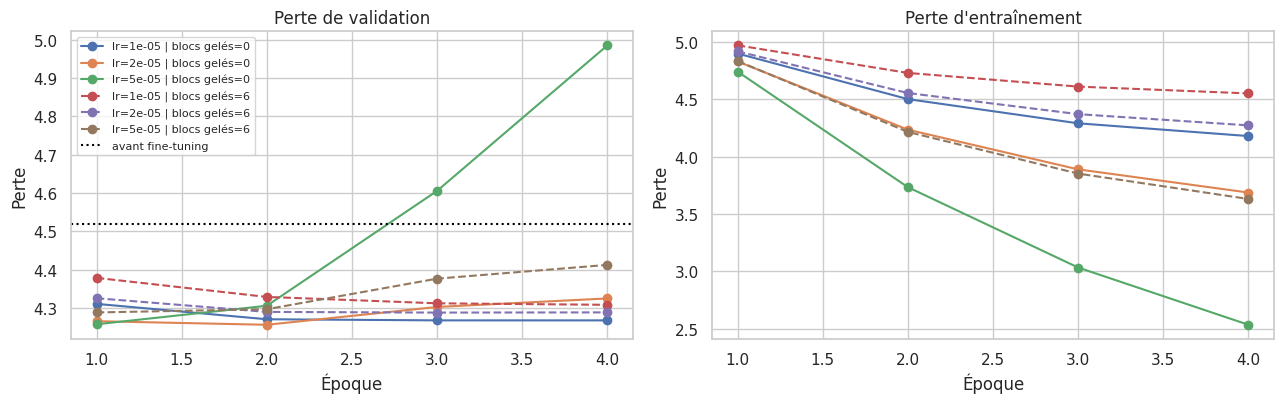

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for key, v in results.items():
    ep = range(1, len(v["history"]["val_loss"]) + 1)
    style = "-" if v["n_frozen"] == 0 else "--"
    axes[0].plot(ep, v["history"]["val_loss"], style, marker="o", label=key)
    axes[1].plot(ep, v["history"]["train_loss"], style, marker="o", label=key)
axes[0].axhline(loss_val_before, color="black", linestyle=":", label="avant fine-tuning")
axes[0].set_title("Perte de validation"); axes[1].set_title("Perte d'entraînement")
for ax in axes: ax.set_xlabel("Époque"); ax.set_ylabel("Perte")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 5. Génération d'un paragraphe à partir d'une phrase

 La fonction `write_paragraph` prend une phrase de départ, la nettoie comme le dataset, puis laisse le modèle écrire la suite (jusqu'à 120 tokens). Le texte généré n'a pas de ponctuation, car le fine-tuning a été fait sur du texte nettoyé (lettres arabes seulement).

### 5.1 Avant / après fine-tuning

On donne les mêmes phrases de départ au modèle pré-entraîné et au modèle fine-tuné, avec la même graine aléatoire, pour comparer. On teste des phrases sur l'éducation, et une phrase **hors sujet** (la dernière) pour voir si le modèle reste capable d'écrire sur autre chose.

In [16]:
prompts = [
    "التعليم في المغرب يعرف",
    "تهدف إصلاحات منظومة التربية والتكوين إلى",
    "يعتبر الهدر المدرسي من أهم المشاكل التي",
    "تضم الجامعة المغربية عدة كليات ومعاهد",
    "يعيش المغرب مباراة كرة القدم",       # hors sujet
]

comparison = []
for p in prompts:
    base_text = write_paragraph(p, base_model)
    tuned_text = write_paragraph(p, model)
    comparison.append({"phrase de départ": p, "pré-entraîné": base_text, "fine-tuné": tuned_text})
    print("=" * 100)
    print("PHRASE DE DÉPART :", p)
    print("\n-- Pré-entraîné :\n", base_text)
    print("\n-- Fine-tuné :\n", tuned_text)

pd.DataFrame(comparison).to_csv(os.path.join(OUT_DIR, "exemples_generation.csv"), index=False, encoding="utf-8-sig")

PHRASE DE DÉPART : التعليم في المغرب يعرف

-- Pré-entraîné :
 التعليم في المغرب يعرف تطورا ملحوظا ، خاصة بعد إقرار اتفاقية التجارة الحرة مع الاتحاد الأوروبي ، حيث أصبحت الصادرات المغربية من المواد الغذائية والسلع الاستهلاكية تحتل المراتب الأولى على الصعيد الدولي .وفي هذا الصدد يقول عبد العالي بوانو المدير العام لمجموعة الحكامة : " لقد عرفت صادراتنا إلى أوروبا ارتفاعا هاما حيث بلغت سنة 2011 حوالي 2 , 6 بالمائة ( 2 , 9 مليون طن ) مقابل 4 , 3 بالمائة خلال نفس الفترة من السنة الماضية أي بانخفاض قدره 0 , 5 نقطة مقارنة بسنة 2010 الذي سجلت فيه صادراتنا بقيمة 1 , 7 مليار درهم مقابل 2 , 8 مليار دولار " مضيفا أن هذه الوضعية جاءت نتيجة ارتفاع سعر الدرهم مقابل الأورو بحوالي

-- Fine-tuné :
 التعليم في المغرب يعرف التعليم العالي بالمغرب تطورا سريعا على المستوى الوطني خلال العقد الماضي حيث ارتفع عدد الطلبة المسجلين لدى الأكاديمية المغربية للعلوم التطبيقية والتكنولوجية من عام إلى سنة مع تزايد الاهتمام بالتعليم العالي والبحث العلمي كما يعد التعليم العالي أحد أعمدة التنمية الاقتصادية والاجتماعية بالممل

**Remarque.** Les deux modèles écrivent un arabe fluide, ce qui n'était pas du tout le cas des RNN de la partie 1. Par contre, **la fluidité ne veut pas dire que le contenu est vrai** : les textes contiennent des chiffres, des noms, des citations et des affirmations inventés (par exemple des pourcentages, un « directeur » qui parle, un classement mondial). Ces textes ne sont donc pas des sources d'information fiables. Pour juger l'effet du fine-tuning, il faut comparer les deux colonnes : plus le texte fine-tuné ressemble à celui du modèle pré-entraîné, plus l'adaptation a été faible.

### 5.2 Effet de la stratégie de décodage

Le modèle donne à chaque étape une probabilité pour chaque token. La façon de choisir le token suivant change beaucoup le texte :

- **greedy** : on prend toujours le plus probable. Résultat souvent répétitif (c'est ce qu'on a vu avec les RNN de la partie 1) ;
- **beam search** : on garde plusieurs candidats en parallèle (ici 5) et on choisit la meilleure phrase complète ;
- **sampling** (`top_p`, `top_k`, `temperature`) : on tire au hasard parmi les tokens probables. Plus la température est haute, plus c'est créatif (et risqué).

On compare les trois sur la même phrase avec le modèle fine-tuné.

In [17]:
prompt = "يعتبر إصلاح التعليم في المغرب"
strategies = {
    "greedy":                         dict(do_sample=False, no_repeat_ngram_size=0, repetition_penalty=1.0),
    "greedy + no_repeat_ngram=3":     dict(do_sample=False, no_repeat_ngram_size=3, repetition_penalty=1.0),
    "beam search (5 faisceaux)":      dict(do_sample=False, num_beams=5, no_repeat_ngram_size=3, repetition_penalty=1.0),
    "sampling (top_p 0,92 ; T 0,8)":  dict(),
    "sampling (T 1,2)":               dict(temperature=1.2),
}
for name, kw in strategies.items():
    print(f"--- {name}")
    print(write_paragraph(prompt, model, max_new_tokens=80, **kw), "\n")

--- greedy
يعتبر إصلاح التعليم في المغرب من بين أهم الإصلاحات التي عرفها المغرب منذ الاستقلال حيث تم التركيز على إصلاح المنظومة التعليمية من خلال إصلاح المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج الدراسية وإعادة هيكلة المناهج 

--- greedy + no_repeat_ngram=3
يعتبر إصلاح التعليم في المغرب من بين أهم الإصلاحات التي عرفها المغرب منذ الاستقلال حيث تم التركيز على إصلاح المنظومة التعليمية من خلال إصلاح المناهج الدراسية وإعادة هيكلة المناهج الدراسية كما تم التركيز أيضا على إصلاح منظومة الدعم التي كانت سببا في تراجع عدد الطلبة في المغرب حيث بلغ عدد الطلبة المسجلين في المدارس العمومية في عام واحد فقط حوالي مليون طالب 

**Remarque.** Le choix du décodage change beaucoup le texte. Le *greedy* tombe vite dans une boucle (« كما تم إحداث عدة معاهد... » se répète), exactement comme les RNN de la partie 1, mais avec une bien meilleure langue. `no_repeat_ngram_size` et le *beam search* limitent les boucles. Le *sampling* donne les textes les plus variés, mais une température trop haute (1,2) les rend moins cohérents. Il n'y a pas de réglage parfait : c'est un compromis entre régularité et créativité.

### 5.3 Essayer ses propres phrases

On peut changer `my_sentence` pour générer un paragraphe à partir de n'importe quelle phrase. On peut aussi modifier la graine pour obtenir un autre texte avec la même phrase.

In [18]:
my_sentence = "أصبح التعليم الرقمي في المغرب"
my_seed = 7

print(write_paragraph(my_sentence, model, max_new_tokens=120, seed=my_seed))

أصبح التعليم الرقمي في المغرب يحتل حيزا مهما على جدول أعمال المجلس الوطني لحقوق الإنسان ، الذي قرر تشكيل لجنة استشارية مكلفة بدراسة وتحليل آثار المحتوى الرقمي للتعليم من أجل التنمية الاقتصادية والاجتماعية والثقافية على الأفراد والأسر والأطفال . فقد شكل هذا القرار تتويجا لمجهودات المجلس الوطني المغربي في تعزيز حماية الأطفال من العنف الأسري وتعزيز إدماجهم في الحياة الاجتماعية والاقتصادية والتعليم في سن مبكرة ضمن الفئة العمرية المستهدفة به في القانون المغربي


## 6. Évaluation : perplexité et BLEU

### 6.1 Perplexité sur le test

On mesure la perte sur le jeu de test (articles jamais vus), avant et après fine-tuning pour mesurer l'effet du fine-tuning.

In [19]:
loss_test_after = evaluate_loss(model, test_loader)
loss_val_after = evaluate_loss(model, val_loader)

ppl = pd.DataFrame({
    "Perte validation":      [loss_val_before, loss_val_after],
    "Perplexité validation": [np.exp(loss_val_before), np.exp(loss_val_after)],
    "Perte test":            [loss_test_before, loss_test_after],
    "Perplexité test":       [np.exp(loss_test_before), np.exp(loss_test_after)],
}, index=["GPT-2 pré-entraîné", "GPT-2 fine-tuné"])
display(ppl.round(3))
ppl.to_csv(os.path.join(OUT_DIR, "perplexite_gpt2.csv"))
print("Le fine-tuning a amélioré la validation." if finetune_improved else "Attention : le modèle fine-tuné est identique au modèle pré-entraîné (aucune amélioration trouvée).")

,Perte validation,Perplexité validation,Perte test,Perplexité test
GPT-2 pré-entraîné,4.520,91.859,4.766,117.487
GPT-2 fine-tuné,4.256,70.531,4.492,89.274


Le fine-tuning a amélioré la validation.


### 6.2 Score BLEU sur les mêmes textes que la partie 1

Pour comparer GPT-2 avec les RNN, on refait **exactement la même expérience** que dans la partie 1 : à partir des 30 premiers mots d'une fenêtre du test, le modèle écrit la suite, et on compare avec les 20 vrais mots suivants. Les fenêtres sont les mêmes (même séparation, même découpage), seule la façon de découper les mots en tokens change. GPT-2 génère des tokens : on décode, on nettoie, puis on garde les 20 premiers mots. Avant le calcul du BLEU, on applique la normalisation des lettres aux deux textes, comme dans la partie 1.

On teste deux décodages pour chaque modèle : **greedy** (le même que dans la partie 1) et **greedy avec `no_repeat_ngram_size=3`** (qui interdit les répétitions).

In [20]:
PROMPT_LEN, TARGET_LEN, EVAL_STRIDE = 30, 20, 25
WINDOW = PROMPT_LEN + TARGET_LEN

def build_windows(indices, stride):
    windows = []
    for i in indices:
        words = df["words"].iloc[i]
        for s in range(0, len(words) - WINDOW + 1, stride):
            windows.append(words[s:s + WINDOW])
    return windows

test_win = build_windows(test_idx, EVAL_STRIDE)
test_prompts = [" ".join(w[:PROMPT_LEN]) for w in test_win]
test_refs = [win[PROMPT_LEN:] for win in test_win]            # vraies suites (mots d'origine)
print("Fenêtres de test :", len(test_win), "(la partie 1 en avait 165)")

smooth = SmoothingFunction().method1
def compute_bleu(references, hypotheses):
    norm = lambda words: [normalize_arabic(w) for w in words]      # même normalisation que la partie 1
    refs = [[norm(r)] for r in references]
    hypotheses = [norm(h) for h in hypotheses]
    return {
        "BLEU-1": corpus_bleu(refs, hypotheses, weights=(1, 0, 0, 0), smoothing_function=smooth),
        "BLEU-2": corpus_bleu(refs, hypotheses, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth),
        "BLEU-4": corpus_bleu(refs, hypotheses, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth),
    }

@torch.no_grad()
def continuations(which_model, prompts_list, batch_size=16, max_new_tokens=60, **gen_kwargs):
    which_model.eval()
    tokenizer.padding_side = "left"          # le remplissage doit être à gauche pour la génération
    hyps = []
    for i in range(0, len(prompts_list), batch_size):
        enc = tokenizer(prompts_list[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        out = which_model.generate(**enc, max_new_tokens=max_new_tokens, pad_token_id=PAD_ID, **gen_kwargs)
        texts = tokenizer.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for t in texts:
            hyps.append(clean_text(t).split()[:TARGET_LEN])
    tokenizer.padding_side = "right"
    return hyps

bleu_rows, gpt_generations = {}, {}
for model_name, which in [("GPT-2 pré-entraîné", base_model), ("GPT-2 fine-tuné", model)]:
    for decoding, kw in [("greedy", dict(do_sample=False)),
                         ("greedy + no_repeat_3", dict(do_sample=False, no_repeat_ngram_size=3))]:
        label = f"{model_name} ({decoding})"
        gpt_generations[label] = continuations(which, test_prompts, **kw)
        bleu_rows[label] = compute_bleu(test_refs, gpt_generations[label])
        print("terminé :", label)

df_bleu_gpt = pd.DataFrame(bleu_rows).T
display(df_bleu_gpt.round(4))

Fenêtres de test : 165 (la partie 1 en avait 165)
terminé : GPT-2 pré-entraîné (greedy)
terminé : GPT-2 pré-entraîné (greedy + no_repeat_3)
terminé : GPT-2 fine-tuné (greedy)
terminé : GPT-2 fine-tuné (greedy + no_repeat_3)


,BLEU-1,BLEU-2,BLEU-4
GPT-2 pré-entraîné (greedy),0.0793,0.0394,0.0130
GPT-2 pré-entraîné (greedy + no_repeat_3),0.0901,0.0400,0.0105
GPT-2 fine-tuné (greedy),0.0971,0.0487,0.0164
GPT-2 fine-tuné (greedy + no_repeat_3),0.0937,0.0442,0.0119


### 6.3 Comparaison avec les modèles de la partie 1

On ajoute au tableau les résultats BLEU des quatre RNN et de la référence minimale, relus dans `bleu_results.csv` (partie 1).

,BLEU-1,BLEU-2,BLEU-4
RNN (partie 1),0.0385,0.0111,0.0006
BiRNN (partie 1),0.0494,0.0089,0.0006
GRU (partie 1),0.0403,0.0113,0.0006
LSTM (partie 1),0.0391,0.0112,0.0006
Référence minimale,0.1227,0.0153,0.0007
GPT-2 pré-entraîné (greedy),0.0793,0.0394,0.0130
GPT-2 pré-entraîné (greedy + no_repeat_3),0.0901,0.0400,0.0105
GPT-2 fine-tuné (greedy),0.0971,0.0487,0.0164
GPT-2 fine-tuné (greedy + no_repeat_3),0.0937,0.0442,0.0119


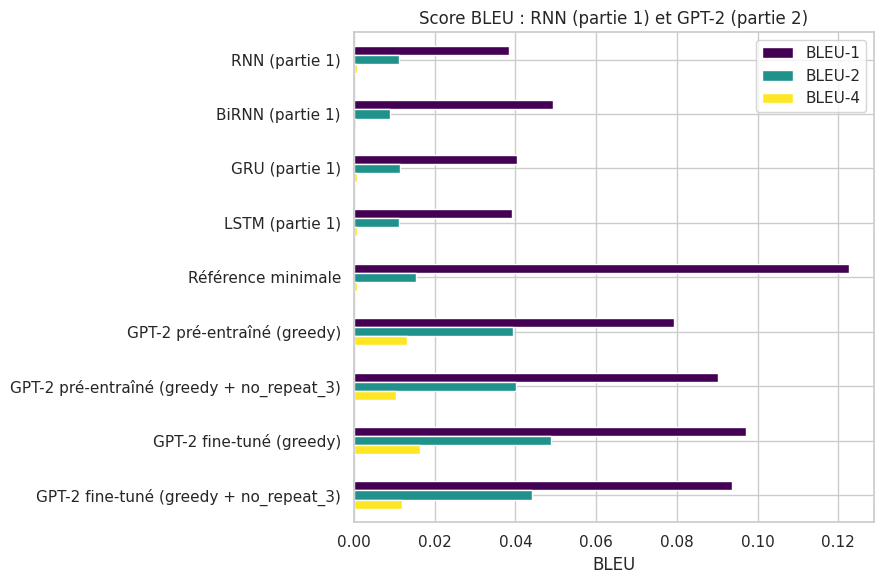

In [21]:
part1_path = os.path.join(PART1_DIR, "bleu_results.csv")
if os.path.exists(part1_path):
    df_part1 = pd.read_csv(part1_path, index_col=0)
    df_part1.index = [f"{name} (partie 1)" if name != "Référence minimale" else name for name in df_part1.index]
    df_compare = pd.concat([df_part1, df_bleu_gpt])
else:
    print("bleu_results.csv introuvable : seuls les résultats de GPT-2 sont affichés.")
    df_compare = df_bleu_gpt

display(df_compare.round(4))
df_compare.to_csv(os.path.join(OUT_DIR, "bleu_comparaison.csv"))

df_compare[["BLEU-1", "BLEU-2", "BLEU-4"]].plot(kind="barh", figsize=(9, 6), colormap="viridis", edgecolor="white")
plt.title("Score BLEU : RNN (partie 1) et GPT-2 (partie 2)")
plt.xlabel("BLEU"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

**Remarque:** Deux observations restent vraies quel que soit le fine-tuning. D'abord, **GPT-2 est bien meilleur que les RNN dès qu'on regarde des groupes de mots** : le BLEU-4 est autour de 0,01, soit environ 20 fois celui des RNN (0,0006), et le BLEU-2 est de l'ordre de 0,04 contre 0,01. Ensuite, le BLEU-1 est moins informatif : la référence minimale (qui écrit seulement les mots les plus fréquents, comme « في » ou « من ») garde un BLEU-1 plus élevé que GPT-2, parce que ces petits mots se retrouvent presque toujours dans la vraie suite. Un modèle qui essaie d'écrire des mots de contenu prend un risque et perd du BLEU-1. Il faut donc surtout regarder BLEU-2 et BLEU-4. Avec 165 fenêtres et une seule référence, les petits écarts entre variantes de GPT-2 ne sont pas significatifs.

### 6.4 Exemples de suites générées

3 exemples du test : le début donné au modèle, la vraie suite, et la suite écrite par GPT-2 avant et après fine-tuning. Il faut lire ces textes : le BLEU ne dit pas si un texte est cohérent, et une suite correcte mais différente de la référence aura un mauvais score.

In [22]:
base_key = "GPT-2 pré-entraîné (greedy + no_repeat_3)"
tuned_key = "GPT-2 fine-tuné (greedy + no_repeat_3)"

for k in [0, len(test_win) // 3, 2 * len(test_win) // 3]:
    print("=" * 100)
    print("DÉBUT        :", test_prompts[k])
    print("RÉEL         :", " ".join(test_refs[k]))
    print("PRÉ-ENTRAÎNÉ :", " ".join(gpt_generations[base_key][k]))
    print("FINE-TUNÉ    :", " ".join(gpt_generations[tuned_key][k]))

DÉBUT        : جامعة ابن زهر هي جامعة مغربية عمومية أسست في عام بمدينة أكادير يبلغ عدد طلبة وطالبات الجامعة حوالي وتتكون هيئتها التدريسية من أستاذا وأستاذا مساعدا وباحثا تعتبر جامعة ابن زهر
RÉEL         : أكبر جامعة بالمغرب فهي تغطي أزيد من من التراب الوطني وتضم شبكة واسعة من المؤسسات الجامعية كما يتوافد إليها الطلبة
PRÉ-ENTRAÎNÉ : من الجامعات المغربية العمومية التي تأسست في مدينة أكادير في عام م تضم الجامعة مجموعة من الأقسام العلمية التي تشمل
FINE-TUNÉ    : جامعة مغربية خاصة في المغرب تأسست سنة في مدينة أكادير في المغرب وهي جامعة حكومية مغربية تأسست سنة تقع في
DÉBUT        : العامة مديرية التعليم العالي والتنمية البيداغوجية مديرية البحث العلمي والابتكار مديرية الاستراتيجيات والنظم المعلوماتية مديرية الشؤون القانونية والمعادلات والمنازعات مديرية الميزانية والشؤون العامة مديرية الموارد البشرية مديرية التعاون والشراكة قائمة
RÉEL         : الوزراء المبادئ يهتدي نظام التربية والتكوين للمملكة المغربية بمبادئ العقيدة الإسلامية وقيمها الرامية لتكون المواطن المتصف بالاستقامة والصلاح المتسم بال

**Remarque.** Dans ces exemples, les suites de GPT-2 sont cohérentes avec le début du texte (une université, une liste de directions ministérielles, des conditions de concours), alors que les RNN répétaient « في المغرب ». Elles ne sont pas identiques à la vraie suite, donc le BLEU reste bas, mais elles sont plausibles : c'est la limite d'un BLEU avec une seule référence.

## 7. Sauvegarde et bilan

### 7.1 Sauvegarde du modèle fine-tuné

On enregistre le modèle et le tokenizer dans Google Drive avec `save_pretrained`. Pour le réutiliser plus tard sans refaire le fine-tuning, il suffit de le recharger avec `from_pretrained(MODEL_DIR)`.

In [23]:
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

config2 = {"base_model": MODEL_NAME, "best_configuration": best_key, "learning_rate": best_run["lr"],
           "frozen_blocks": best_run["n_frozen"], "dropout": DROPOUT, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
           "best_epoch": best_run["info"]["best_epoch"], "max_tokens": MAX_TOKENS,
           "improved_over_pretrained": bool(finetune_improved),
           "split_seed": int(split_seed), "generation": {k: v for k, v in GEN_KWARGS.items()}}
with open(os.path.join(OUT_DIR, "config_partie2.json"), "w", encoding="utf-8") as f:
    json.dump(config2, f, ensure_ascii=False, indent=2)

print("Modèle enregistré dans :", MODEL_DIR)
print(sorted(os.listdir(OUT_DIR)))

Modèle enregistré dans : /content/drive/MyDrive/Projet_NLP_Education_Maroc/resultats_partie2/gpt2_education_maroc
['bleu_comparaison.csv', 'config_partie2.json', 'exemples_generation.csv', 'gpt2_education_maroc', 'gpt2_finetuning_grille.csv', 'perplexite_gpt2.csv']


### 7.2 Bilan

**Ce qu'on a fait**

- Chargement d'un GPT-2 pré-entraîné pour l'arabe (AraGPT2-base) avec la bibliothèque `transformers`.
- Fine-tuning sur notre dataset personnalisé (passages sur l'éducation au Maroc), avec la même séparation par article que la partie 1.
- Génération de paragraphes à partir d'une phrase, avec comparaison avant / après fine-tuning et de plusieurs stratégies de décodage.
- Évaluation avec la perplexité et le BLEU, et comparaison avec les RNN de la partie 1.

**Ce qu'on a appris sur le fine-tuning**

- Un premier essai (taux 5e-5, petits batchs, modèle entier) a rendu le modèle **moins bon** que le modèle de départ (perte de validation 4,75 contre 4,52). Un fine-tuning n'est pas forcément meilleur : il faut toujours comparer avec le modèle de départ sur la validation.
- Une grille avec des taux plus petits et des couches gelées a été stable mais presque sans effet (4,493 contre 4,520). Une anomalie est restée : une perte d'entraînement de 8 à 10 en première époque, que l'on a attribuée au dropout, d'où le diagnostic de la section 4.2 et sa désactivation.
- Avec très peu de données (246 passages), le gain attendu d'un fine-tuning est modeste : le modèle pré-entraîné connaît déjà bien l'arabe.

**Limites**

- Le dataset est très petit (246 passages d'entraînement) : le fine-tuning est surtout une adaptation du vocabulaire et du style, et le modèle peut apprendre les passages par cœur.
- Le texte généré n'a pas de ponctuation, car on a gardé uniquement les lettres arabes pour rester cohérent avec la partie 1. On pourrait fine-tuner sur du texte avec ponctuation pour avoir des phrases plus naturelles.
- Le BLEU n'a qu'une seule référence par exemple : il est bas même pour une suite correcte.
- Un seul fine-tuning (une seule graine), donc les petites différences ne sont pas forcément significatives.
- Un modèle génératif peut inventer des informations fausses : les textes générés ne doivent pas être considérés comme des faits sur l'éducation au Maroc.

**Idées pour améliorer**

- Ajouter plus de textes (plus d'articles Wikipédia ou de revues) et garder la ponctuation.
- Tester un modèle plus grand (`aragpt2-medium`) ou des techniques légères comme LoRA, qui fine-tunent moins de paramètres.
- Évaluer avec des métriques plus adaptées à la génération (par exemple BERTScore) ou une relecture humaine.